# code_003 · Prediction and discovery on related observations

**Book:** Chapter 1, section 1.2. **Purpose:** executable concept experiments, not a complete estimator hyperparameter course. All data and helper definitions are inside this notebook. Synthetic values are invented for teaching and provide no engineering validation.

Use the repository [quickstart](../README.md) and pinned environment. Restart the kernel and run all cells in order. Verified target: CPython 3.14.3 and scikit-learn 1.9.0, CPU only; no files, downloads, API keys or project imports are needed during execution. Allow a minute for execution plus time to reason through the prompts. Actual time, environment and checks are recorded at the end and in the [Chapter 1 execution report](../CHAPTER_01_EXECUTION.md).

Read each prediction prompt before running its experiment. Controls are identified as task, data-generation, model or decision controls; they are not interchangeable. The [stable directory](../CODE_EXAMPLES.md#code_003) links this example to the manuscript.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=101
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
assert sklearn.__version__=='1.9.0','Use the verified pinned environment.'
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':100,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="prediction"></a>
## Different questions require different targets

We generate independent synthetic members with a dimensionless load index and an age in years. A continuous response is an invented displacement in mm; an actionable-finding label is sampled from a separate logistic probability. These are not an engineering law or observed damage. We predeclare a mean baseline versus linear regression and a prior baseline versus logistic classification. No hyperparameter search is performed. A 60/20/20 stratified split allocates development training, validation and a sealed final assessment; validation checks the fixed workflow without changing it.

`LinearRegression.fit` estimates coefficients and `predict` returns a continuous value. `LogisticRegression.fit` estimates a class model; `predict_proba` returns probability columns ordered by `classes_`, and `predict` returns labels. We use raw numeric units here for an introductory fixed model; conditioning and scaling choices are studied later. **Predict:** can a low displacement MAE establish that a finding classifier is calibrated?


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.dummy import DummyRegressor,DummyClassifier
from sklearn.metrics import mean_absolute_error,balanced_accuracy_score,log_loss,average_precision_score,adjusted_rand_score,roc_auc_score
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
rng=np.random.default_rng(SEED)
X=np.c_[rng.uniform(0,1,1200),rng.uniform(0,40,1200)]
y_reg=1+3*X[:,0]+.03*X[:,1]+rng.normal(0,.35,len(X))
p=1/(1+np.exp(-(-3+4*X[:,0]+.025*X[:,1])))
y_cls=rng.binomial(1,p)
ids=np.arange(len(X));dev,test=train_test_split(ids,test_size=.2,stratify=y_cls,random_state=SEED)
tr,va=train_test_split(dev,test_size=.25,stratify=y_cls[dev],random_state=SEED+1)
assert not(set(tr)&set(va) or set(tr)&set(test) or set(va)&set(test))
reg=LinearRegression().fit(X[tr],y_reg[tr]);reg0=DummyRegressor().fit(X[tr],y_reg[tr])
clf=LogisticRegression(C=1,max_iter=1000,random_state=SEED).fit(X[tr],y_cls[tr])
clf0=DummyClassifier(strategy='prior').fit(X[tr],y_cls[tr])
print('Fixed validation checks: regression MAE',mean_absolute_error(y_reg[va],reg.predict(X[va])),
 '| classification log loss',log_loss(y_cls[va],clf.predict_proba(X[va])))


Fixed validation checks: regression MAE 0.27396414061011487 | classification log loss 0.5551259748299903


<a id="ranking"></a>
## Ranking changes the use of a score

The crew can inspect only twenty test members. We predeclare descending class-1 probability as a ranking, without refitting a separate ranker. Precision at twenty means findings in those twenty divided by twenty; recall at twenty means those findings divided by all findings in the evaluated cohort. Average precision summarizes a different, threshold-varying ranking property. None is a causal estimate of avoided damage.

The next cell is the single final supervised assessment of these already fixed models. The scatter plots show continuous prediction error and probability versus a known *simulated* probability; this known truth is available only because we generated the data. **Predict:** can classification accuracy stay the same while the useful ordering of the highest-risk cases changes?


mean_baseline_MAE_mm          0.860957
linear_MAE_mm                 0.312459
prior_log_loss                0.673028
logistic_log_loss             0.507663
logistic_balanced_accuracy    0.758681
precision_at_20               0.750000
recall_at_20                  0.156250
average_precision             0.721484
Name: Final fixed supervised assessment, dtype: float64

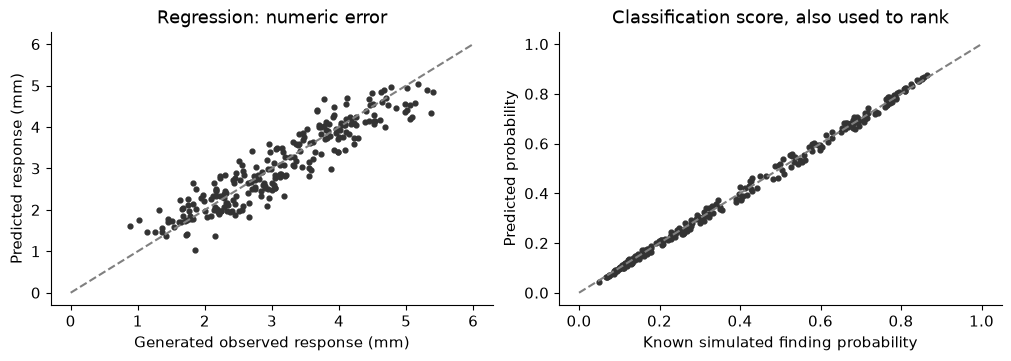

In [3]:
final={
 'mean_baseline_MAE_mm':float(mean_absolute_error(y_reg[test],reg0.predict(X[test]))),
 'linear_MAE_mm':float(mean_absolute_error(y_reg[test],reg.predict(X[test]))),
 'prior_log_loss':float(log_loss(y_cls[test],clf0.predict_proba(X[test]))),
 'logistic_log_loss':float(log_loss(y_cls[test],clf.predict_proba(X[test]))),
 'logistic_balanced_accuracy':float(balanced_accuracy_score(y_cls[test],clf.predict(X[test])))}
score=clf.predict_proba(X[test])[:,1];order=np.argsort(-score,kind='stable');k=20
final['precision_at_20']=float(y_cls[test][order[:k]].mean())
final['recall_at_20']=float(y_cls[test][order[:k]].sum()/y_cls[test].sum())
final['average_precision']=float(average_precision_score(y_cls[test],score))
display(pd.Series(final,name='Final fixed supervised assessment'))
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].scatter(y_reg[test],reg.predict(X[test]),s=12,color='.2');ax[0].plot([0,6],[0,6],'--',color='.5')
ax[0].set(xlabel='Generated observed response (mm)',ylabel='Predicted response (mm)',title='Regression: numeric error')
ax[1].scatter(p[test],score,s=12,color='.2');ax[1].plot([0,1],[0,1],'--',color='.5')
ax[1].set(xlabel='Known simulated finding probability',ylabel='Predicted probability',title='Classification score, also used to rank')
plt.show();RESULTS['supervised_final']=final


<a id="discovery"></a>
## Discover operating regimes and unusual observations

We now ask different questions of sensor summaries. Three simulated regimes produce two-channel clouds. K-means minimizes squared distance to three centroids; its integer cluster names have no intrinsic meaning. `fit` sees no regime labels. We compare with simulated regime labels using adjusted Rand agreement only as an external check, and compare two versus three clusters as a declared mechanism experiment, not a chosen winner on the supervised test set.

An isolation forest separately learns reference behaviour from normal training records and scores a new batch containing injected anomalies. We negate `score_samples` so larger means more unusual and evaluate its score against the injected flags. The anomaly flags are not failure diagnoses; a rare observation may be valid. **Predict:** will merely multiplying the second channel by ten change distance-based clusters? That is a representation control, distinct from `n_clusters` (a model control).


Agreement before/after changing channel units: 0.45555419462872104


/var/folders/69/6ttm620n24b3krnk3377jrmh0000gn/T/ipykernel_8323/3776137564.py:18: UserWarning: You passed an edgecolor/edgecolors ('.2') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  mask=labels3==group;ax[0].scatter(*Z[mask].T,marker=marker,s=18,label=f'Cluster {group}',facecolors='none' if marker!='x' else '.2',edgecolors='.2')


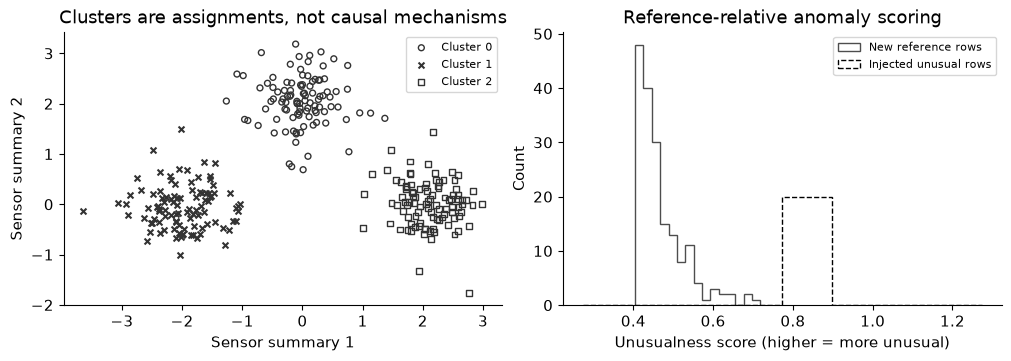

,clusters,inertia,ARI_against_simulated_regime
0,2,537.919695,0.555385
1,3,123.391001,0.989983


Injected-anomaly score ROC AUC: 1.0


In [4]:
centres=np.array([[-2.,0.],[0.,2.],[2.,0.]])
regime=np.repeat(np.arange(3),100)
Z=centres[regime]+rng.normal(0,.45,(300,2))
cluster_rows=[];labels3=None
for n in [2,3]:
 km=KMeans(n_clusters=n,n_init=10,random_state=SEED).fit(Z)
 cluster_rows.append({'clusters':n,'inertia':km.inertia_,'ARI_against_simulated_regime':adjusted_rand_score(regime,km.labels_)})
 if n==3:labels3=km.labels_
scaled=KMeans(n_clusters=3,n_init=10,random_state=SEED).fit(Z*np.array([1.,10.]))
print('Agreement before/after changing channel units:',adjusted_rand_score(labels3,scaled.labels_))
normal_train=rng.normal(0,1,(500,2));normal_new=rng.normal(0,1,(180,2));injected=rng.normal(4,.3,(20,2))
new=np.vstack([normal_new,injected]);flags=np.r_[np.zeros(180,dtype=int),np.ones(20,dtype=int)]
iso=IsolationForest(n_estimators=100,random_state=SEED).fit(normal_train)
unusual=-iso.score_samples(new);auc=float(roc_auc_score(flags,unusual))
assert unusual.shape==(200,) and np.isfinite(unusual).all()
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
for group,marker in zip(range(3),['o','x','s']):
 mask=labels3==group;ax[0].scatter(*Z[mask].T,marker=marker,s=18,label=f'Cluster {group}',facecolors='none' if marker!='x' else '.2',edgecolors='.2')
ax[0].set(title='Clusters are assignments, not causal mechanisms',xlabel='Sensor summary 1',ylabel='Sensor summary 2');ax[0].legend(fontsize=8)
ax[1].hist(unusual[flags==0],bins=15,histtype='step',color='.3',label='New reference rows')
ax[1].hist(unusual[flags==1],bins=8,histtype='step',color='black',ls='--',label='Injected unusual rows')
ax[1].set(xlabel='Unusualness score (higher = more unusual)',ylabel='Count',title='Reference-relative anomaly scoring');ax[1].legend(fontsize=8)
plt.show();display(pd.DataFrame(cluster_rows));print('Injected-anomaly score ROC AUC:',auc)
RESULTS['clustering']=cluster_rows;RESULTS['injected_anomaly_auc']=auc


## Exercises and interpretation

1. Change the inspection capacity from 20 to 10 on a new development cohort. Predict how precision and recall can move differently; do not retune on the revealed final test.
2. Replace the continuous response with an ordered damage grade. Explain why regression on arbitrary grade numbers may misstate error costs.
3. Relabel the cluster IDs by a permutation and verify adjusted Rand agreement is unchanged. Explain why cluster 2 is not automatically the most damaged regime.
4. Introduce a dense group of unusual-but-valid operating records. Compare rarity with abnormality and write a review policy.
5. Draw a possible common cause of both temperature and sensor amplitude. State why a predictive association does not prove the effect of changing temperature.

**Optional hint:** different outputs can share the same features while answering different questions. Supervised labels, cluster objectives and anomaly references determine what can be concluded. The full constructor labs belong in later chapters; no model here is claimed optimal.


## Interpretation, limits and next steps

The printed tables and figures are observations from this executed synthetic experiment. Describe the mechanism they demonstrate before comparing individual numbers. Fixed seeds make the teaching run reproducible; they do not establish performance in a new population. No deployment or physical validity guarantee follows from passing these checks. For model-specific controls, use the official documentation and the later model chapters; [code_001](../CODE_EXAMPLES.md#code_001) is a full decision-tree parameter laboratory.

**Troubleshooting:** a version assertion means the selected kernel differs from the pinned environment. Restart and run all cells rather than borrowing state from a different notebook. Missing or repeated timestamps require an explicit observation policy, not a silent row reorder. When adapting an experiment, record its new assumptions, selection rule and untouched assessment evidence. Initial package installation may use the internet; these cells do not.


In [5]:
EXECUTION_SUMMARY={'example_id':'code_003','versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU',
 'seed':SEED,'concepts_demonstrated':['regression', 'classification', 'ranking and capacity metrics', 'clustering', 'anomaly reference', 'descriptive versus causal claims'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:',json.dumps(EXECUTION_SUMMARY,sort_keys=True))


EXECUTION_SUMMARY_JSON: {"concepts_demonstrated": ["regression", "classification", "ranking and capacity metrics", "clustering", "anomaly reference", "descriptive versus causal claims"], "elapsed_seconds": 3.73, "example_id": "code_003", "hardware": "Darwin arm64 CPU", "results": {"clustering": [{"ARI_against_simulated_regime": 0.555384648952137, "clusters": 2, "inertia": 537.9196949857032}, {"ARI_against_simulated_regime": 0.9899831669528851, "clusters": 3, "inertia": 123.39100116424916}], "injected_anomaly_auc": 1.0, "supervised_final": {"average_precision": 0.7214842885035699, "linear_MAE_mm": 0.31245913458654395, "logistic_balanced_accuracy": 0.7586805555555556, "logistic_log_loss": 0.5076625079693712, "mean_baseline_MAE_mm": 0.8609572596617922, "precision_at_20": 0.75, "prior_log_loss": 0.6730277176053282, "recall_at_20": 0.15625}}, "seed": 101, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}